In [1]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn imbalanced-learn joblib


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Mac\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    precision_recall_curve
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

import joblib
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv("data/raw/PS_20174392719_1491204439457_log.csv")

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.shape


(6362620, 11)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [6]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [7]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [8]:
df['isFraud'].value_counts()


isFraud
0    6354407
1       8213
Name: count, dtype: int64

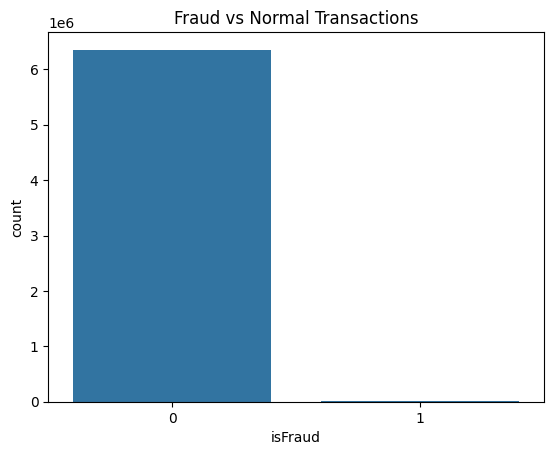

In [9]:
sns.countplot(x='isFraud', data=df)
plt.title('Fraud vs Normal Transactions')
plt.show()


In [10]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [11]:
pd.crosstab(df['type'], df['isFraud'])

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [12]:
fraud_by_type = pd.crosstab(
    df['type'],
    df['isFraud'],
    normalize='index'
) * 100

fraud_by_type

isFraud,0,1
type,,
CASH_IN,100.000000,0.000000
CASH_OUT,99.816045,0.183955
DEBIT,100.000000,0.000000
PAYMENT,100.000000,0.000000
TRANSFER,99.231201,0.768799


In [13]:
df.columns.to_list()

['step',
 'type',
 'amount',
 'nameOrig',
 'oldbalanceOrg',
 'newbalanceOrig',
 'nameDest',
 'oldbalanceDest',
 'newbalanceDest',
 'isFraud',
 'isFlaggedFraud']

In [14]:
df['isFlaggedFraud'].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [ ]:
df = df.drop(['nameOrig', 'nameDest', 'isFlaggedFraud'], axis=1)




In [ ]:
df['balanceDiffOrig'] = df['oldbalanceOrg'] - df['newbalanceOrig']

df['balanceDiffDest'] = df['newbalanceDest'] - df['oldbalanceDest']


In [ ]:
df = pd.get_dummies(df, columns=['type'], drop_first=True)




In [22]:
df.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0,False,False,True,False
1,1,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0,False,False,True,False
2,1,181.00,181.0,0.00,0.0,0.0,1,181.00,0.0,False,False,False,True
3,1,181.00,181.0,0.00,21182.0,0.0,1,181.00,-21182.0,True,False,False,False
4,1,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0,False,False,True,False


In [46]:
df_sample = df.sample(n=1000000, random_state=42)

df_sample.shape


(1000000, 10)

In [47]:
df_sample.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balanceDiffDest,type
3737323,278,330218.42,20866.00,351084.42,452419.57,122201.15,0,-330218.42,-330218.42,CASH_IN
264914,15,11647.08,30370.00,18722.92,0.00,0.00,0,11647.08,0.00,PAYMENT
85647,10,152264.21,106589.00,258853.21,201303.01,49038.80,0,-152264.21,-152264.21,CASH_IN
5899326,403,1551760.63,0.00,0.00,3198359.45,4750120.08,0,0.00,1551760.63,TRANSFER
2544263,206,78172.30,2921331.58,2999503.88,415821.90,337649.60,0,-78172.30,-78172.30,CASH_IN


In [50]:
df_sample.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1000000 entries, 3737323 to 1023694
Data columns (total 10 columns):
 #   Column           Non-Null Count    Dtype  
---  ------           --------------    -----  
 0   step             1000000 non-null  int64  
 1   amount           1000000 non-null  float64
 2   oldbalanceOrg    1000000 non-null  float64
 3   newbalanceOrig   1000000 non-null  float64
 4   oldbalanceDest   1000000 non-null  float64
 5   newbalanceDest   1000000 non-null  float64
 6   isFraud          1000000 non-null  int64  
 7   balanceDiffOrig  1000000 non-null  float64
 8   balanceDiffDest  1000000 non-null  float64
 9   type             1000000 non-null  object 
dtypes: float64(7), int64(2), object(1)
memory usage: 83.9+ MB


In [51]:
df_sample["isFraud"].value_counts(normalize=True) * 100

isFraud
0    99.8734
1     0.1266
Name: proportion, dtype: float64

In [52]:
X = df_sample.drop('isFraud', axis=1)

y = df_sample['isFraud']


In [53]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)


In [54]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

In [55]:
splits = {

    'Training': y_train,

    'Validation': y_val,

    'Testing': y_test

}

for name, target in splits.items():

    print("\n", name)

    print(target.value_counts())

    print(target.value_counts(normalize=True) * 100)



 Training
isFraud
0    699114
1       886
Name: count, dtype: int64
isFraud
0    99.873429
1     0.126571
Name: proportion, dtype: float64

 Validation
isFraud
0    149810
1       190
Name: count, dtype: int64
isFraud
0    99.873333
1     0.126667
Name: proportion, dtype: float64

 Testing
isFraud
0    149810
1       190
Name: count, dtype: int64
isFraud
0    99.873333
1     0.126667
Name: proportion, dtype: float64


In [56]:
def undersample_training_data(X, y, ratio=30):

    train_data = X.copy()

    train_data['target'] = y.values

    fraud_data = train_data[
        train_data['target'] == 1
    ]

    normal_data = train_data[
        train_data['target'] == 0
    ]

    n_normal = min(
        len(normal_data),
        len(fraud_data) * ratio
    )

    normal_sample = normal_data.sample(
        n=n_normal,
        random_state=42
    )

    balanced_data = pd.concat(
        [fraud_data, normal_sample]
    )

    balanced_data = balanced_data.sample(
        frac=1,
        random_state=42
    )

    X_resampled = balanced_data.drop(
        columns=['target']
    )

    y_resampled = balanced_data['target']

    return X_resampled, y_resampled


In [57]:
X_train_balanced, y_train_balanced = undersample_training_data(
    X_train,
    y_train,
    ratio=30
)

print("Original Training Shape:", X_train.shape)

print("Balanced Training Shape:", X_train_balanced.shape)

print("\nNew Class Distribution:")

print(y_train_balanced.value_counts())


Original Training Shape: (700000, 9)
Balanced Training Shape: (27466, 9)

New Class Distribution:
target
0    26580
1      886
Name: count, dtype: int64


In [58]:
categorical_features = X_train_balanced.select_dtypes(
    include=['object']
).columns.tolist()

numerical_features = X_train_balanced.select_dtypes(
    include=['number']
).columns.tolist()

print("Categorical Features:")

print(categorical_features)

print("\nNumerical Features:")

print(numerical_features)


Categorical Features:
['type']

Numerical Features:
['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'balanceDiffOrig', 'balanceDiffDest']


In [43]:
df['type'] = np.select(
    [
        df['type_CASH_OUT'],
        df['type_DEBIT'],
        df['type_PAYMENT'],
        df['type_TRANSFER']
    ],
    [
        'CASH_OUT',
        'DEBIT',
        'PAYMENT',
        'TRANSFER'
    ],
    default='CASH_IN'
)


In [44]:
df.drop(
    columns=[
        'type_CASH_OUT',
        'type_DEBIT',
        'type_PAYMENT',
        'type_TRANSFER'
    ],
    inplace=True
)


In [45]:
print(df['type'].unique())

print(df['type'].value_counts())


['PAYMENT' 'TRANSFER' 'CASH_OUT' 'DEBIT' 'CASH_IN']
type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [59]:
df_sample.isnull().sum()

step               0
amount             0
oldbalanceOrg      0
newbalanceOrig     0
oldbalanceDest     0
newbalanceDest     0
isFraud            0
balanceDiffOrig    0
balanceDiffDest    0
type               0
dtype: int64

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical Features
numeric_transformer = Pipeline([
    ('scaler', StandardScaler())
])

# Categorical Features
categorical_transformer = Pipeline([
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        drop='first'
    ))
])

# Combine Both Transformers
preprocessor = ColumnTransformer([

    ('num', numeric_transformer, numerical_features),

    ('cat', categorical_transformer, categorical_features)

])

print("Preprocessing Pipeline Created Successfully!")



Preprocessing Pipeline Created Successfully!


In [80]:
!pip install scikit-learn xgboost joblib


  Using cached xgboost-3.2.0-py3-none-win_amd64.whl.metadata (2.1 kB)
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
   ---------------------------------------- 0.8/101.7 MB 2.6 MB/s eta 0:00:40
    --------------------------------------- 1.6/101.7 MB 3.2 MB/s eta 0:00:32
    --------------------------------------- 2.4/101.7 MB 3.4 MB/s eta 0:00:29
   - -------------------------------------- 3.1/101.7 MB 3.5 MB/s eta 0:00:28
   - -------------------------------------- 3.9/101.7 MB 3.7 MB/s eta 0:00:27
   - -------------------------------------- 5.0/101.7 MB 3.7 MB/s eta 0:00:27
   -- ------------------------------------- 5.8/101.7 MB 3.7 MB/s eta 0:00:27
   -- ------------------------------------- 6.3/101.7 MB 3.5 MB/s eta 0:00:27
   -- ------------------------------------- 7.1/101.7 MB 3.5 MB/s eta 0:00:27
   -- ------------------------------------- 7.6/101.7 MB 3.4 MB/s eta 0:00:28
   --- -


[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Mac\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [82]:
from xgboost import XGBClassifier
scale_pos_weight = (
    (y_train == 0).sum()
    / (y_train == 1).sum()
)

models = {

    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBClassifier(
        scale_pos_weight=scale_pos_weight,
        eval_metric="aucpr",
        random_state=42,
        n_jobs=-1
    )
}

print("Models Defined Successfully")

Models Defined Successfully


In [ ]:
########
pipelines = {}

for name, model in models.items():

    pipeline = Pipeline([

        ('preprocessing', preprocessor),

        ('classifier', model)

    ])

    pipelines[name] = pipeline

print("All Model Pipelines Created!")


All Model Pipelines Created!


In [ ]:
######
trained_models = {}

for name, pipeline in pipelines.items():

    print("\nTraining:", name)

    pipeline.fit(
        X_train_balanced,
        y_train_balanced
    )

    trained_models[name] = pipeline

    print(name, "Training Completed!")



Training: Logistic Regression
Logistic Regression Training Completed!

Training: Random Forest
Random Forest Training Completed!


In [83]:
param_grids = {

    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10]
    },

    "Decision Tree": {
        "model__max_depth": [5, 10, 15],
        "model__min_samples_split": [2, 10],
        "model__min_samples_leaf": [1, 5]
    },

    "Random Forest": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [10, 20],
        "model__min_samples_leaf": [1, 5]
    },

    "XGBoost": {
        "model__n_estimators": [100, 200],
        "model__max_depth": [3, 5],
        "model__learning_rate": [0.05, 0.1],
        "model__subsample": [0.8, 1.0]
    }
}


In [85]:
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

best_models = {}

grid_results = []

for name, model in models.items():

    print(f"\nTraining {name}...")

    pipeline = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("model", model)
        ]
    )

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="average_precision",
        cv=cv,
        n_jobs=1,
        verbose=1,
        refit=True
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    grid_results.append({
        "Model": name,
        "Best PR-AUC CV": grid.best_score_,
        "Best Parameters": grid.best_params_
    })

    print("Best Parameters:", grid.best_params_)

    print("Best CV PR-AUC:", grid.best_score_)


Training Logistic Regression...
Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best Parameters: {'model__C': 0.01}
Best CV PR-AUC: 0.5813037268637896

Training Decision Tree...
Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best Parameters: {'model__max_depth': 15, 'model__min_samples_leaf': 5, 'model__min_samples_split': 2}
Best CV PR-AUC: 0.7891089672333882

Training Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best Parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 5, 'model__n_estimators': 200}
Best CV PR-AUC: 0.911435491677429

Training XGBoost...
Fitting 3 folds for each of 16 candidates, totalling 48 fits
Best Parameters: {'model__learning_rate': 0.1, 'model__max_depth': 5, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best CV PR-AUC: 0.922166047581567


In [86]:
results = []

for name, model in best_models.items():

    y_pred_proba = model.predict_proba(X_val)[:, 1]

    y_pred = (y_pred_proba >= 0.5).astype(int)

    results.append({

        "Model": name,

        "PR-AUC": average_precision_score(
            y_val,
            y_pred_proba
        ),

        "Precision": precision_score(
            y_val,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            y_pred,
            zero_division=0
        ),

        "F1-Score": f1_score(
            y_val,
            y_pred,
            zero_division=0
        )
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

results_df

,Model,PR-AUC,Precision,Recall,F1-Score
3,XGBoost,0.925161,0.441463,0.952632,0.603333
2,Random Forest,0.904373,0.937107,0.784211,0.853868
1,Decision Tree,0.785701,0.476744,0.863158,0.614232
0,Logistic Regression,0.573876,0.025173,0.900000,0.048976


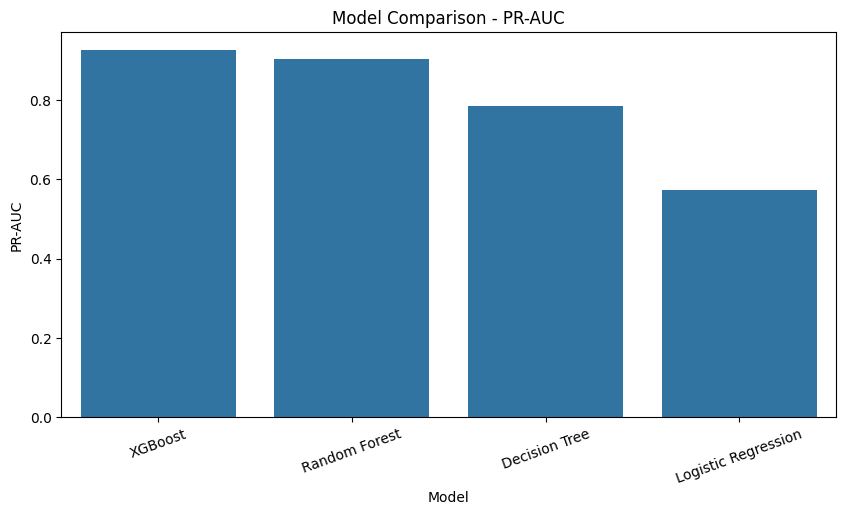

In [88]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="PR-AUC"
)

plt.title("Model Comparison - PR-AUC")
plt.xticks(rotation=20)
plt.show()


In [89]:
best_model_name = results_df.iloc[0]["Model"]

best_model = best_models[best_model_name]

print("Best Model:", best_model_name)

Best Model: XGBoost


In [90]:
COST_FN = 1000

COST_FP = 50




val_probabilities = best_model.predict_proba(
    X_val
)[:, 1]

thresholds = np.arange(
    0.01,
    1.00,
    0.01
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        val_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        predictions,
        labels=[0, 1]
    ).ravel()

    total_cost = (
        fn * COST_FN +
        fp * COST_FP
    )

    threshold_results.append({

        "Threshold": threshold,

        "TP": tp,
        "FP": fp,
        "TN": tn,
        "FN": fn,

        "Precision": precision_score(
            y_val,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val,
            predictions,
            zero_division=0
        ),

        "Total Cost": total_cost
    })

threshold_df = pd.DataFrame(
    threshold_results
)

best_threshold_row = threshold_df.loc[
    threshold_df["Total Cost"].idxmin()
]

best_threshold = float(
    best_threshold_row["Threshold"]
)

print("Best Threshold:", best_threshold)

print("Minimum Cost:", best_threshold_row["Total Cost"])

print(best_threshold_row)

Best Threshold: 0.47000000000000003
Minimum Cost: 19450.0
Threshold          0.470000
TP               183.000000
FP               249.000000
TN            149561.000000
FN                 7.000000
Precision          0.423611
Recall             0.963158
Total Cost     19450.000000
Name: 46, dtype: float64


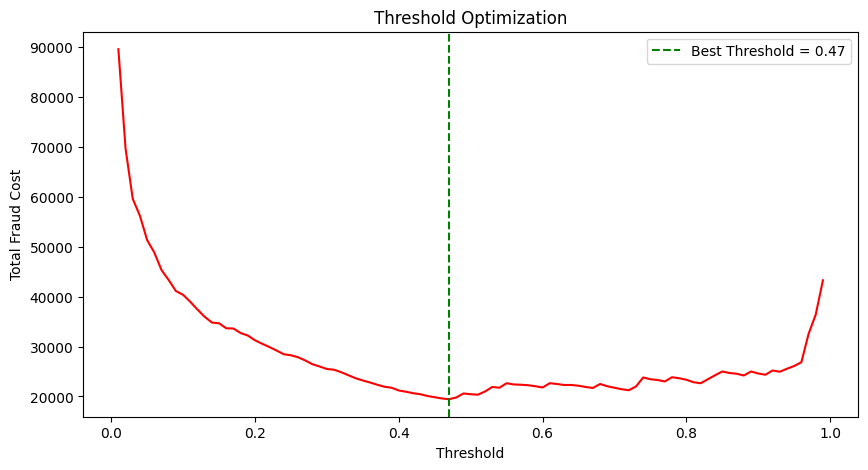

In [91]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Total Cost"],
    color="red"
)

plt.axvline(
    best_threshold,
    color="green",
    linestyle="--",
    label=f"Best Threshold = {best_threshold:.2f}"
)

plt.xlabel("Threshold")

plt.ylabel("Total Fraud Cost")

plt.title("Threshold Optimization")

plt.legend()

plt.show()

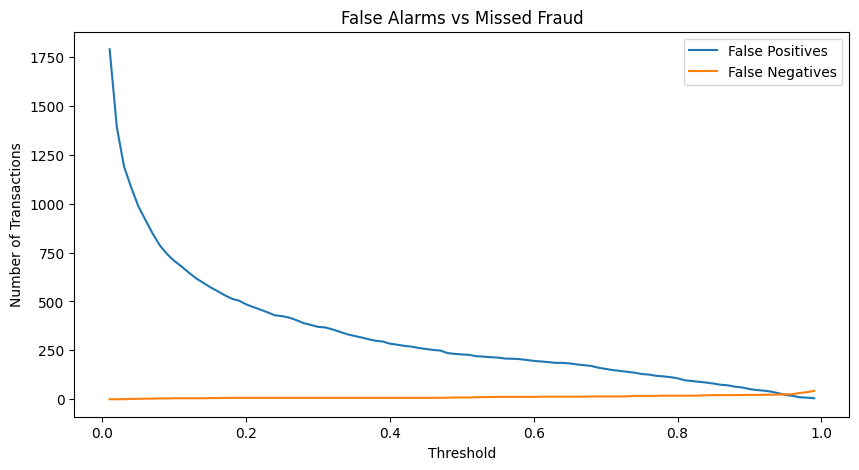

In [92]:
plt.figure(figsize=(10, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FP"],
    label="False Positives"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FN"],
    label="False Negatives"
)

plt.xlabel("Threshold")

plt.ylabel("Number of Transactions")

plt.title("False Alarms vs Missed Fraud")

plt.legend()

plt.show()

In [94]:
from sklearn.metrics import roc_auc_score


test_probabilities = best_model.predict_proba(
    X_test
)[:, 1]

test_predictions = (
    test_probabilities >= best_threshold
).astype(int)

print("Best Model:", best_model_name)

print("Best Threshold:", best_threshold)

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

print(
    "PR-AUC:",
    average_precision_score(
        y_test,
        test_probabilities
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        test_probabilities
    )
)

Best Model: XGBoost
Best Threshold: 0.47000000000000003

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    149810
           1       0.43      0.98      0.60       190

    accuracy                           1.00    150000
   macro avg       0.71      0.99      0.80    150000
weighted avg       1.00      1.00      1.00    150000

PR-AUC: 0.9410361398876947
ROC-AUC: 0.9998257441882524


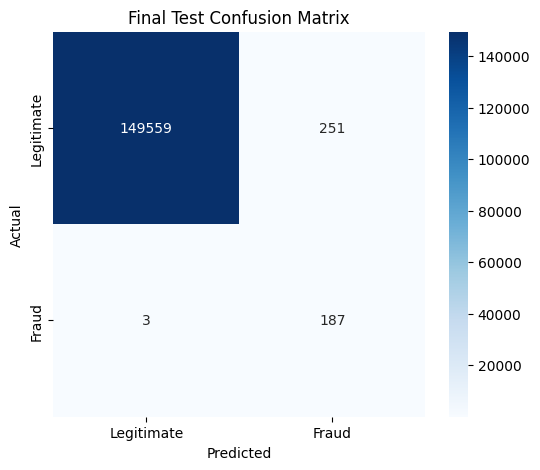

In [95]:
cm = confusion_matrix(
    y_test,
    test_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("Final Test Confusion Matrix")

plt.show()

In [96]:
tn, fp, fn, tp = cm.ravel()

test_cost = (
    fn * COST_FN +
    fp * COST_FP
)

print("True Positives:", tp)

print("False Positives:", fp)

print("True Negatives:", tn)

print("False Negatives:", fn)

print("Total Test Cost:", test_cost)

print("Average Cost per Transaction:", test_cost / len(y_test))

True Positives: 187
False Positives: 251
True Negatives: 149559
False Negatives: 3
Total Test Cost: 15550
Average Cost per Transaction: 0.10366666666666667


In [97]:

import os


os.makedirs("models", exist_ok=True)

model_bundle = {

    "model": best_model,

    "model_name": best_model_name,

    "threshold": best_threshold,

    "cost_fn": COST_FN,

    "cost_fp": COST_FP,

    "features": X_train.columns.tolist()
}

joblib.dump(
    model_bundle,
    "models/best_fraud_model.pkl"
)

print("Model Saved Successfully!")

Model Saved Successfully!


In [99]:
!pip install streamlit plotly

  Using cached streamlit-1.67.0-py3-none-any.whl.metadata (10 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached altair-6.3.0-py3-none-any.whl.metadata (11 kB)
  Using cached pydeck-0.9.3-py2.py3-none-any.whl.metadata (4.2 kB)
  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
  Using cached pyarrow-26.0.1-cp311-cp311-win_amd64.whl.metadata (3.0 kB)
  Using cached itsdangerous-2.2.0-py3-none-any.whl.metadata (1.9 kB)
  Using cached jsonschema-4.26.0-py3-none-any.whl.metadata (7.6 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
  Using cached jsonschema_specifications-2025.9.1-py3-none-any.whl.metadata (2.9 kB)
  Using cached referencing-0.37.0-py3-none-any.whl.metadata (2.8 kB)
Using cached streamlit-1.67.0-py3-none-any.whl (11.2 MB)
Using cached altair-6.3.0-py3-none-any.whl (797 kB)
Using cached itsdangerous-2.2.0-py3-none-any.whl (16 kB)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
Using 

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
paddlepaddle 3.1.1 requires opt-einsum==3.3.0, but you have opt-einsum 3.4.0 which is incompatible.
tensorflow-intel 2.17.1 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 7.36.2 which is incompatible.

[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: C:\Users\Mac\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [100]:
results_df.to_csv(
    "models/model_comparison.csv",
    index=False
)

threshold_df.to_csv(
    "models/threshold_results.csv",
    index=False
)